In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

PyTorch version: 2.13.0+cu130
Torchvision version: 0.28.0+cu130


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [3]:
print("Current directory:")
print(os.getcwd())

print("\nFiles and folders:")
print(os.listdir())

Current directory:
/home/aahana/24CD3002_AI_ML_Application_Assignments/Assignment-7

Files and folders:
['.ipynb_checkpoints', '24cd3002_assgn-7.ipynb']


In [4]:
import gdown

url = "https://drive.google.com/uc?id=151WbWURL8IPXqhxi8vLCx7pmtvchegpZ"

output = "gun_dataset.zip"

gdown.download(url, output, quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=151WbWURL8IPXqhxi8vLCx7pmtvchegpZ
From (redirected): https://drive.google.com/uc?id=151WbWURL8IPXqhxi8vLCx7pmtvchegpZ&confirm=t&uuid=3daaa9f3-6ad8-4525-8caf-98ae3e431f46
To: /home/aahana/24CD3002_AI_ML_Application_Assignments/Assignment-7/gun_dataset.zip
100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 78.7M/78.7M [00:07<00:00, 9.91MB/s]


'gun_dataset.zip'

In [5]:
print("Dataset file exists:", os.path.exists("gun_dataset.zip"))

if os.path.exists("gun_dataset.zip"):
    print("Size:", os.path.getsize("gun_dataset.zip") / (1024 * 1024), "MB")

Dataset file exists: True
Size: 75.01649475097656 MB


In [6]:
import zipfile

with zipfile.ZipFile("gun_dataset.zip", "r") as zip_ref:
    zip_ref.extractall("gun_dataset")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [7]:
for root, dirs, files in os.walk("gun_dataset"):
    level = root.replace("gun_dataset", "").count(os.sep)
    indent = "  " * level
    print(indent + os.path.basename(root) + "/")

    for file in files[:10]:
        print(indent + "  " + file)

    if level >= 2:
        dirs[:] = []

gun_dataset/
  __MACOSX/
    PistolData_merged/
      ._pistol_images
      ._pistol_annotations
      ._.DS_Store
  PistolData_merged/
    .DS_Store
    pistol_images/
      2963.jpg
      1666.jpg
      1963.jpg
      3289.jpg
      2954.jpg
      3660.jpg
      1812.jpg
      2024.jpg
      565.jpg
      3589.jpg
    pistol_annotations/
      541.txt
      1158.txt
      1750.txt
      1424.txt
      976.txt
      995.txt
      1799.txt
      2127.txt
      1226.txt
      1384.txt


In [8]:
image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

image_files = []

for root, dirs, files in os.walk("gun_dataset"):
    for file in files:
        if file.lower().endswith(image_extensions):
            image_files.append(os.path.join(root, file))

print("Total images:", len(image_files))
print("\nFirst 10 images:")

for img in image_files[:10]:
    print(img)

Total images: 7406

First 10 images:
gun_dataset/__MACOSX/PistolData_merged/pistol_images/._2909.jpg
gun_dataset/__MACOSX/PistolData_merged/pistol_images/._1329.jpg
gun_dataset/__MACOSX/PistolData_merged/pistol_images/._364.jpg
gun_dataset/__MACOSX/PistolData_merged/pistol_images/._435.jpg
gun_dataset/__MACOSX/PistolData_merged/pistol_images/._2417.jpg
gun_dataset/__MACOSX/PistolData_merged/pistol_images/._433.jpg
gun_dataset/__MACOSX/PistolData_merged/pistol_images/._1905.jpg
gun_dataset/__MACOSX/PistolData_merged/pistol_images/._3201.jpg
gun_dataset/__MACOSX/PistolData_merged/pistol_images/._943.jpg
gun_dataset/__MACOSX/PistolData_merged/pistol_images/._503.jpg


In [11]:
image_dir = "gun_dataset/PistolData_merged/pistol_images"
annotation_dir = "gun_dataset/PistolData_merged/pistol_annotations"

print("Image directory exists:", os.path.exists(image_dir))
print("Annotation directory exists:", os.path.exists(annotation_dir))

Image directory exists: True
Annotation directory exists: True


In [48]:
image_files = sorted([
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

print("Number of images:", len(image_files))
print("First 10 images:")
print(image_files[:10])

Number of images: 3703
First 10 images:
['1.jpg', '10.jpg', '100.jpg', '1000.jpg', '1001.jpg', '1002.jpg', '1003.jpg', '1004.jpg', '1005.jpg', '1006.jpg']


In [49]:
annotation_files = sorted([
    f for f in os.listdir(annotation_dir)
    if f.lower().endswith(".txt")
])

print("Number of annotations:", len(annotation_files))
print("First 10 annotations:")
print(annotation_files[:10])

Number of annotations: 3703
First 10 annotations:
['1.txt', '10.txt', '100.txt', '1000.txt', '1001.txt', '1002.txt', '1003.txt', '1004.txt', '1005.txt', '1006.txt']


In [50]:
pairs = []

for image_file in image_files:
    base_name = os.path.splitext(image_file)[0]
    annotation_file = base_name + ".txt"

    annotation_path = os.path.join(annotation_dir, annotation_file)

    if os.path.exists(annotation_path):
        pairs.append((image_file, annotation_file))

print("Number of image-annotation pairs:", len(pairs))
print("First 5 pairs:")
print(pairs[:5])

Number of image-annotation pairs: 3703
First 5 pairs:
[('1.jpg', '1.txt'), ('10.jpg', '10.txt'), ('100.jpg', '100.txt'), ('1000.jpg', '1000.txt'), ('1001.jpg', '1001.txt')]


In [51]:
image_file, annotation_file = pairs[0]

annotation_path = os.path.join(annotation_dir, annotation_file)

with open(annotation_path, "r") as f:
    annotation = f.read().strip()

print("Image:", image_file)
print("Annotation file:", annotation_file)
print("Annotation contents:", annotation)

Image: 1.jpg
Annotation file: 1.txt
Annotation contents: 1 0.4253846153846154 0.2447973713033954 0.22153846153846152 0.2814895947426068


In [52]:
for image_file, annotation_file in pairs[:10]:
    annotation_path = os.path.join(annotation_dir, annotation_file)

    with open(annotation_path, "r") as f:
        values = f.read().strip().split()

    print(annotation_file, "→", values)

1.txt → ['1', '0.4253846153846154', '0.2447973713033954', '0.22153846153846152', '0.2814895947426068']
10.txt → ['1', '0.4983922829581993', '0.4907407407407407', '0.3665594855305466', '0.4506172839506173']
100.txt → ['1', '0.6466602129719264', '0.28387096774193543', '0.08131655372700872', '0.05935483870967742']
1000.txt → ['1', '0.5747967479674796', '0.39390243902439026', '0.27804878048780485', '0.3341463414634146']
1001.txt → ['1', '0.5061538461538462', '0.4229559748427673', '0.3353846153846154', '0.3050314465408805']
1002.txt → ['1', '0.4972727272727273', '0.41226993865030676', '0.9709090909090908', '0.792638036809816']
1003.txt → ['1', '0.6112716763005781', '0.3324074074074074', '0.33815028901734107', '0.2462962962962963']
1004.txt → ['1', '0.5499999999999999', '0.4414414414414415', '0.492', '0.6426426426426427']
1005.txt → ['1', '0.5545454545454546', '0.6404545454545455', '0.8181818181818182', '0.7172727272727273']
1006.txt → ['1', '0.49166666666666664', '0.3745387453874539', '0.90

In [53]:
from collections import Counter

class_counts = Counter()
zero_boxes = 0
nonzero_boxes = 0

for image_file, annotation_file in pairs:
    annotation_path = os.path.join(annotation_dir, annotation_file)

    with open(annotation_path, "r") as f:
        values = list(map(float, f.read().strip().split()))

    class_id = int(values[0])
    bbox = values[1:5]

    class_counts[class_id] += 1

    if bbox == [0.0, 0.0, 0.0, 0.0]:
        zero_boxes += 1
    else:
        nonzero_boxes += 1

print("Class distribution:", class_counts)
print("Zero bounding boxes:", zero_boxes)
print("Non-zero bounding boxes:", nonzero_boxes)

Class distribution: Counter({1: 2704, 0: 999})
Zero bounding boxes: 999
Non-zero bounding boxes: 2704


Class: 1
Bounding box: [0.4253846153846154, 0.2447973713033954, 0.22153846153846152, 0.2814895947426068]
Image size: (416, 416)


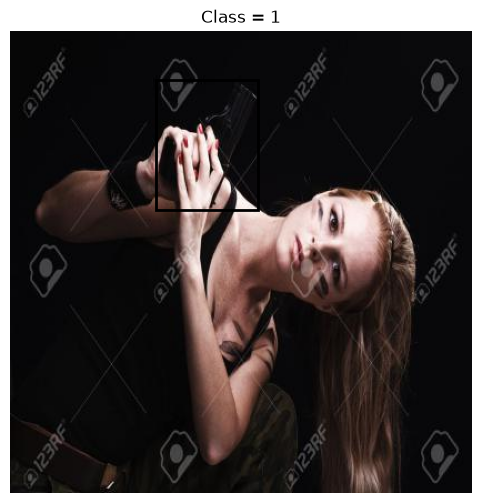

In [54]:
image_file, annotation_file = pairs[0]

image_path = os.path.join(image_dir, image_file)
annotation_path = os.path.join(annotation_dir, annotation_file)

image = Image.open(image_path).convert("RGB")

with open(annotation_path, "r") as f:
    values = list(map(float, f.read().strip().split()))

class_id = int(values[0])
xc, yc, w, h = values[1:5]

print("Class:", class_id)
print("Bounding box:", [xc, yc, w, h])
print("Image size:", image.size)

plt.figure(figsize=(6, 6))
plt.imshow(image)

if class_id == 1:
    img_w, img_h = image.size

    x = (xc - w / 2) * img_w
    y = (yc - h / 2) * img_h
    box_w = w * img_w
    box_h = h * img_h

    rectangle = plt.Rectangle(
        (x, y),
        box_w,
        box_h,
        fill=False,
        linewidth=2
    )

    plt.gca().add_patch(rectangle)

plt.title(f"Class = {class_id}")
plt.axis("off")
plt.show()

In [55]:
from sklearn.model_selection import train_test_split

train_pairs, test_pairs = train_test_split(
    pairs,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print("Total pairs:", len(pairs))
print("Training pairs:", len(train_pairs))
print("Testing pairs:", len(test_pairs))

Total pairs: 3703
Training pairs: 2962
Testing pairs: 741


In [56]:
def get_class_distribution(data_pairs):
    counts = Counter()

    for image_file, annotation_file in data_pairs:
        annotation_path = os.path.join(annotation_dir, annotation_file)

        with open(annotation_path, "r") as f:
            values = list(map(float, f.read().strip().split()))

        class_id = int(values[0])
        counts[class_id] += 1

    return counts


print("Train:", get_class_distribution(train_pairs))
print("Validation:", get_class_distribution(val_pairs))
print("Test:", get_class_distribution(test_pairs))

Train: Counter({1: 2162, 0: 800})
Validation: Counter({1: 415, 0: 140})
Test: Counter({1: 542, 0: 199})


In [57]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

print(transform)

Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
)


In [58]:
class PistolDetectionDataset(Dataset):

    def __init__(
        self,
        pairs,
        image_dir,
        annotation_dir,
        transform=None
    ):
        self.pairs = pairs
        self.image_dir = image_dir
        self.annotation_dir = annotation_dir
        self.transform = transform

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):

        image_file, annotation_file = self.pairs[idx]

        image_path = os.path.join(
            self.image_dir,
            image_file
        )

        annotation_path = os.path.join(
            self.annotation_dir,
            annotation_file
        )

        image = Image.open(image_path).convert("RGB")

        with open(annotation_path, "r") as f:
            values = list(
                map(float, f.read().strip().split())
            )

        class_id = int(values[0])

        bbox = torch.tensor(
            values[1:5],
            dtype=torch.float32
        )

        if self.transform:
            image = self.transform(image)

        return (
            image,
            bbox,
            torch.tensor(class_id, dtype=torch.float32)
        )

In [59]:
train_dataset = PistolDetectionDataset(
    train_pairs,
    image_dir,
    annotation_dir,
    transform
)

print("Training dataset size:", len(train_dataset))

Training dataset size: 2962


In [60]:
val_dataset = PistolDetectionDataset(
    val_pairs,
    image_dir,
    annotation_dir,
    transform
)

print("Validation dataset size:", len(val_dataset))

Validation dataset size: 555


In [61]:
test_dataset = PistolDetectionDataset(
    test_pairs,
    image_dir,
    annotation_dir,
    transform
)

print("Test dataset size:", len(test_dataset))

Test dataset size: 741


In [62]:
for i in range(len(train_dataset)):

    image, bbox, class_id = train_dataset[i]

    if class_id.item() == 1:
        print("Index:", i)
        print("Image shape:", image.shape)
        print("Bounding box:", bbox.numpy())
        print("Class:", int(class_id.item()))
        break

Index: 1
Image shape: torch.Size([3, 224, 224])
Bounding box: [0.553125  0.5416667 0.69375   0.6      ]
Class: 1


In [63]:
for i in range(len(train_dataset)):

    image, bbox, class_id = train_dataset[i]

    if class_id.item() == 0:
        print("Index:", i)
        print("Image shape:", image.shape)
        print("Bounding box:", bbox.numpy())
        print("Class:", int(class_id.item()))
        break

Index: 0
Image shape: torch.Size([3, 224, 224])
Bounding box: [0. 0. 0. 0.]
Class: 0


In [64]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 93
Validation batches: 18
Test batches: 24


In [65]:
images, bboxes, classes = next(iter(train_loader))

print("Images:", images.shape)
print("Bounding boxes:", bboxes.shape)
print("Classes:", classes.shape)

print("\nFirst 5 bounding boxes:")
print(bboxes[:5])

print("\nFirst 5 classes:")
print(classes[:5])

Images: torch.Size([32, 3, 224, 224])
Bounding boxes: torch.Size([32, 4])
Classes: torch.Size([32])

First 5 bounding boxes:
tensor([[0.4977, 0.4995, 0.9614, 0.9760],
        [0.0000, 0.0000, 0.0000, 0.0000],
        [0.6145, 0.5068, 0.6789, 0.6906],
        [0.4906, 0.4917, 0.9438, 0.9333],
        [0.0000, 0.0000, 0.0000, 0.0000]])

First 5 classes:
tensor([1., 0., 1., 1., 0.])


In [66]:
import torch
import torch.nn as nn

class CustomCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

        self.bbox_regressor = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 4),
            nn.Sigmoid()
        )

    def forward(self, x):
        features = self.features(x)

        class_output = self.classifier(features)
        bbox_output = self.bbox_regressor(features)

        return class_output, bbox_output

In [67]:
model = CustomCNN().to(device)

print(model)

CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affin

In [68]:
total_params = sum(p.numel() for p in model.parameters())

print("Total parameters:", total_params)

Total parameters: 455813


In [69]:
classification_loss_fn = nn.BCEWithLogitsLoss()
bbox_loss_fn = nn.SmoothL1Loss()

In [70]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

num_epochs = 15

In [71]:
from tqdm import tqdm

train_history = []
val_history = []

for epoch in range(num_epochs):

    # =========================
    # TRAIN
    # =========================

    model.train()

    running_loss = 0.0
    running_cls_loss = 0.0
    running_bbox_loss = 0.0

    for images, bboxes, classes in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{num_epochs}"
    ):

        images = images.to(device, non_blocking=True)
        bboxes = bboxes.to(device, non_blocking=True)
        classes = classes.to(device, non_blocking=True)

        optimizer.zero_grad()

        class_logits, bbox_preds = model(images)

        classes_float = classes.float().unsqueeze(1)

        # Classification loss
        cls_loss = classification_loss_fn(
            class_logits,
            classes_float
        )

        # Bounding box loss only for positive images
        positive_mask = classes == 1

        if positive_mask.any():

            bbox_loss = bbox_loss_fn(
                bbox_preds[positive_mask],
                bboxes[positive_mask]
            )

        else:
            bbox_loss = torch.tensor(
                0.0,
                device=device
            )

        # Combined loss
        loss = cls_loss + bbox_loss

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        running_cls_loss += cls_loss.item()
        running_bbox_loss += bbox_loss.item()

    avg_loss = running_loss / len(train_loader)
    avg_cls_loss = running_cls_loss / len(train_loader)
    avg_bbox_loss = running_bbox_loss / len(train_loader)

    train_history.append(avg_loss)

    # =========================
    # VALIDATION
    # =========================

    model.eval()

    val_loss = 0.0

    with torch.no_grad():

        for images, bboxes, classes in val_loader:

            images = images.to(device)
            bboxes = bboxes.to(device)
            classes = classes.to(device)

            class_logits, bbox_preds = model(images)

            classes_float = classes.float().unsqueeze(1)

            cls_loss = classification_loss_fn(
                class_logits,
                classes_float
            )

            positive_mask = classes == 1

            if positive_mask.any():

                bbox_loss = bbox_loss_fn(
                    bbox_preds[positive_mask],
                    bboxes[positive_mask]
                )

            else:

                bbox_loss = torch.tensor(
                    0.0,
                    device=device
                )

            loss = cls_loss + bbox_loss

            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)

    val_history.append(avg_val_loss)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {avg_loss:.4f} | "
        f"Cls: {avg_cls_loss:.4f} | "
        f"BBox: {avg_bbox_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f}"
    )

Epoch 1/15: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████| 93/93 [00:10<00:00,  8.61it/s]


Epoch [1/15] Train Loss: 0.3064 | Cls: 0.2791 | BBox: 0.0272 | Val Loss: 0.1795


Epoch 2/15: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████| 93/93 [00:10<00:00,  9.11it/s]


Epoch [2/15] Train Loss: 0.2405 | Cls: 0.2139 | BBox: 0.0266 | Val Loss: 0.2625


Epoch 3/15: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████| 93/93 [00:10<00:00,  8.80it/s]


...

Epoch [13/15] Train Loss: 0.0987 | Cls: 0.0767 | BBox: 0.0220 | Val Loss: 0.0747


Epoch 14/15: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████| 93/93 [00:10<00:00,  9.00it/s]


Epoch [14/15] Train Loss: 0.0943 | Cls: 0.0720 | BBox: 0.0223 | Val Loss: 0.1509


Epoch 15/15: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████| 93/93 [00:10<00:00,  9.09it/s]


Epoch [15/15] Train Loss: 0.0907 | Cls: 0.0690 | BBox: 0.0216 | Val Loss: 0.0789


In [72]:
torch.save(
    model.state_dict(),
    "custom_cnn_pistol_detection.pth"
)

print("Custom CNN model saved.")

Custom CNN model saved.


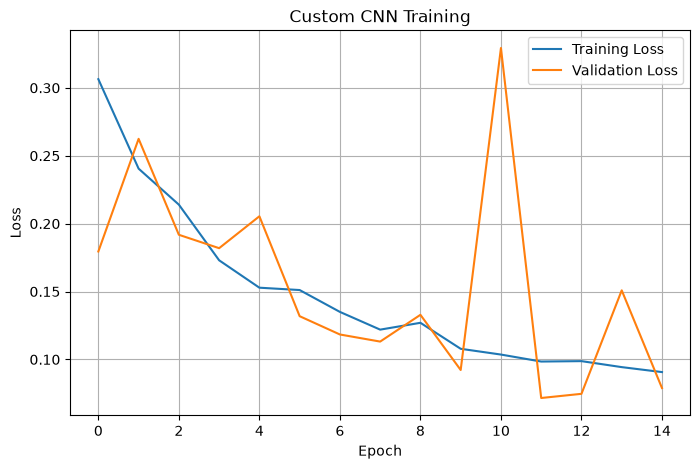

In [73]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(train_history, label="Training Loss")
plt.plot(val_history, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Custom CNN Training")
plt.legend()
plt.grid()

plt.show()

In [74]:
train_pairs, temp_pairs = train_test_split(
    pairs,
    test_size=0.30,
    random_state=42,
    shuffle=True
)

val_pairs, test_pairs = train_test_split(
    temp_pairs,
    test_size=0.50,
    random_state=42,
    shuffle=True
)

print("Train:", len(train_pairs))
print("Validation:", len(val_pairs))
print("Test:", len(test_pairs))

Train: 2592
Validation: 555
Test: 556


In [75]:
print(len(train_pairs))
print(len(val_pairs))
print(len(test_pairs))
print(len(train_pairs) + len(val_pairs) + len(test_pairs))

2592
555
556
3703


In [76]:
train_dataset = PistolDetectionDataset(
    train_pairs,
    image_dir,
    annotation_dir,
    transform
)

val_dataset = PistolDetectionDataset(
    val_pairs,
    image_dir,
    annotation_dir,
    transform
)

test_dataset = PistolDetectionDataset(
    test_pairs,
    image_dir,
    annotation_dir,
    transform
)

print("Training dataset size:", len(train_dataset))
print("Validation dataset size:", len(val_dataset))
print("Test dataset size:", len(test_dataset))

Training dataset size: 2592
Validation dataset size: 555
Test dataset size: 556


In [77]:
print("Train:", get_class_distribution(train_pairs))
print("Validation:", get_class_distribution(val_pairs))
print("Test:", get_class_distribution(test_pairs))

Train: Counter({1: 1875, 0: 717})
Validation: Counter({1: 415, 0: 140})
Test: Counter({1: 414, 0: 142})


In [78]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 81
Validation batches: 18
Test batches: 18


In [79]:
images, bboxes, classes = next(iter(train_loader))

print("Images shape:", images.shape)
print("Bounding boxes shape:", bboxes.shape)
print("Classes shape:", classes.shape)

print("\nFirst 5 bounding boxes:")
print(bboxes[:5])

print("\nFirst 5 classes:")
print(classes[:5])

Images shape: torch.Size([32, 3, 224, 224])
Bounding boxes shape: torch.Size([32, 4])
Classes shape: torch.Size([32])

First 5 bounding boxes:
tensor([[0.5620, 0.6141, 0.6423, 0.4783],
        [0.4850, 0.4140, 0.7300, 0.6497],
        [0.0000, 0.0000, 0.0000, 0.0000],
        [0.3454, 0.2292, 0.0802, 0.1042],
        [0.5000, 0.4776, 0.9969, 0.9507]])

First 5 classes:
tensor([1., 1., 0., 1., 1.])


In [80]:
import torch
import torch.nn as nn

class CustomCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        # Classification head
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

        # Bounding-box regression head
        self.bbox_regressor = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 4),
            nn.Sigmoid()
        )

    def forward(self, x):

        features = self.features(x)

        class_output = self.classifier(features)
        bbox_output = self.bbox_regressor(features)

        return class_output, bbox_output

In [81]:
model = CustomCNN().to(device)

print(model)

total_params = sum(
    p.numel() for p in model.parameters()
)

print("\nTotal parameters:", total_params)

CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affin

In [82]:
classification_loss_fn = nn.BCEWithLogitsLoss()

bbox_loss_fn = nn.SmoothL1Loss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

num_epochs = 15

print("Loss functions and optimizer ready.")

Loss functions and optimizer ready.


In [83]:
model.eval()

with torch.no_grad():

    sample_images, sample_bboxes, sample_classes = next(
        iter(train_loader)
    )

    sample_images = sample_images.to(device)

    class_output, bbox_output = model(sample_images)

print("Input shape:", sample_images.shape)
print("Classification output:", class_output.shape)
print("Bounding-box output:", bbox_output.shape)

Input shape: torch.Size([32, 3, 224, 224])
Classification output: torch.Size([32, 1])
Bounding-box output: torch.Size([32, 4])


In [84]:
from tqdm import tqdm

train_losses = []
val_losses = []

train_cls_losses = []
train_bbox_losses = []

val_cls_losses = []
val_bbox_losses = []

In [85]:
for epoch in range(num_epochs):

    model.train()

    total_loss = 0.0
    total_cls_loss = 0.0
    total_bbox_loss = 0.0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{num_epochs}"
    )

    for images, bboxes, classes in progress_bar:

        images = images.to(device, non_blocking=True)
        bboxes = bboxes.to(device, non_blocking=True)
        classes = classes.to(device, non_blocking=True)

        optimizer.zero_grad()

        class_logits, bbox_preds = model(images)

        # Classification target
        class_targets = classes.unsqueeze(1)

        # Classification loss
        cls_loss = classification_loss_fn(
            class_logits,
            class_targets
        )

        # Bounding box loss only for pistol images
        positive_mask = classes == 1

        if positive_mask.any():

            bbox_loss = bbox_loss_fn(
                bbox_preds[positive_mask],
                bboxes[positive_mask]
            )

        else:

            bbox_loss = torch.tensor(
                0.0,
                device=device
            )

        # Total loss
        loss = cls_loss + bbox_loss

        loss.backward()

        optimizer.step()

        total_loss += loss.item()
        total_cls_loss += cls_loss.item()
        total_bbox_loss += bbox_loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    avg_loss = total_loss / len(train_loader)
    avg_cls_loss = total_cls_loss / len(train_loader)
    avg_bbox_loss = total_bbox_loss / len(train_loader)

    train_losses.append(avg_loss)
    train_cls_losses.append(avg_cls_loss)
    train_bbox_losses.append(avg_bbox_loss)

    print(
        f"\nEpoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {avg_loss:.4f} | "
        f"Cls Loss: {avg_cls_loss:.4f} | "
        f"BBox Loss: {avg_bbox_loss:.4f}"
    )

Epoch 1/15: 100%|█████████████████████████████████████████████████████████████████████████████████████████████| 81/81 [00:16<00:00,  4.95it/s, loss=0.1425]



Epoch 1/15 | Train Loss: 0.3060 | Cls Loss: 0.2789 | BBox Loss: 0.0272


Epoch 2/15: 100%|█████████████████████████████████████████████████████████████████████████████████████████████| 81/81 [00:07<00:00, 10.94it/s, loss=0.4221]



Epoch 2/15 | Train Loss: 0.2162 | Cls Loss: 0.1901 | BBox Loss: 0.0261


Epoch 3/15: 100%|█████████████████████████████████████████████████████████████████████████████████████████████| 81/81 [00:07<00:00, 10.99it/s, loss=0.1501]


...


Epoch 13/15 | Train Loss: 0.1084 | Cls Loss: 0.0864 | BBox Loss: 0.0220


Epoch 14/15: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 81/81 [00:07<00:00, 10.98it/s, loss=0.0438]



Epoch 14/15 | Train Loss: 0.1023 | Cls Loss: 0.0809 | BBox Loss: 0.0214


Epoch 15/15: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 81/81 [00:07<00:00, 11.03it/s, loss=0.1122]


Epoch 15/15 | Train Loss: 0.0968 | Cls Loss: 0.0750 | BBox Loss: 0.0218


In [86]:
model.eval()

val_total_loss = 0.0
val_total_cls_loss = 0.0
val_total_bbox_loss = 0.0

with torch.no_grad():

    for images, bboxes, classes in val_loader:

        images = images.to(device, non_blocking=True)
        bboxes = bboxes.to(device, non_blocking=True)
        classes = classes.to(device, non_blocking=True)

        class_logits, bbox_preds = model(images)

        class_targets = classes.unsqueeze(1)

        cls_loss = classification_loss_fn(
            class_logits,
            class_targets
        )

        positive_mask = classes == 1

        if positive_mask.any():

            bbox_loss = bbox_loss_fn(
                bbox_preds[positive_mask],
                bboxes[positive_mask]
            )

        else:

            bbox_loss = torch.tensor(
                0.0,
                device=device
            )

        loss = cls_loss + bbox_loss

        val_total_loss += loss.item()
        val_total_cls_loss += cls_loss.item()
        val_total_bbox_loss += bbox_loss.item()


avg_val_loss = val_total_loss / len(val_loader)
avg_val_cls_loss = val_total_cls_loss / len(val_loader)
avg_val_bbox_loss = val_total_bbox_loss / len(val_loader)

val_losses.append(avg_val_loss)
val_cls_losses.append(avg_val_cls_loss)
val_bbox_losses.append(avg_val_bbox_loss)

print("Validation Loss:", avg_val_loss)
print("Validation Classification Loss:", avg_val_cls_loss)
print("Validation BBox Loss:", avg_val_bbox_loss)

Validation Loss: 0.09196308255195618
Validation Classification Loss: 0.07023144399540292
Validation BBox Loss: 0.02173163855655326


In [87]:
model_path = "custom_cnn_pistol_detection.pth"

torch.save(
    model.state_dict(),
    model_path
)

print("Model saved successfully:")
print(model_path)

Model saved successfully:
custom_cnn_pistol_detection.pth


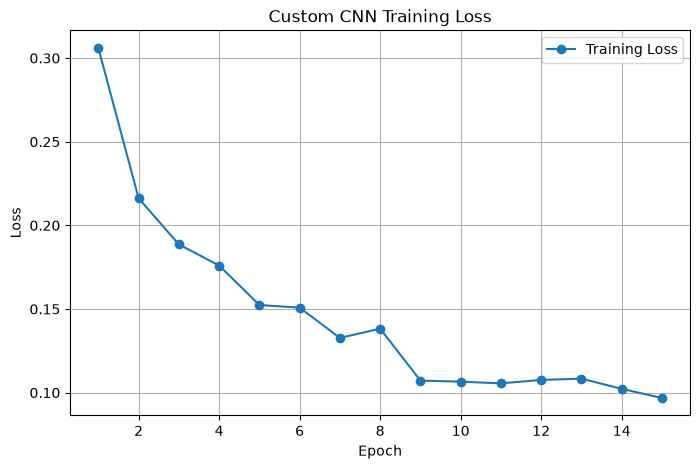

In [88]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Custom CNN Training Loss")

plt.legend()
plt.grid(True)

plt.show()

In [89]:
model = CustomCNN().to(device)

model.load_state_dict(
    torch.load(
        "custom_cnn_pistol_detection.pth",
        map_location=device
    )
)

model.eval()

print("Custom CNN loaded successfully.")

Custom CNN loaded successfully.


In [90]:
def calculate_iou(box1, box2):
    """
    Boxes are in [xc, yc, w, h] format.
    Coordinates are normalized to [0, 1].
    """

    xc1, yc1, w1, h1 = box1
    xc2, yc2, w2, h2 = box2

    # Convert box 1
    x1_min = xc1 - w1 / 2
    y1_min = yc1 - h1 / 2
    x1_max = xc1 + w1 / 2
    y1_max = yc1 + h1 / 2

    # Convert box 2
    x2_min = xc2 - w2 / 2
    y2_min = yc2 - h2 / 2
    x2_max = xc2 + w2 / 2
    y2_max = yc2 + h2 / 2

    # Intersection
    inter_xmin = max(x1_min, x2_min)
    inter_ymin = max(y1_min, y2_min)
    inter_xmax = min(x1_max, x2_max)
    inter_ymax = min(y1_max, y2_max)

    inter_w = max(0, inter_xmax - inter_xmin)
    inter_h = max(0, inter_ymax - inter_ymin)

    intersection = inter_w * inter_h

    # Areas
    area1 = max(0, x1_max - x1_min) * max(0, y1_max - y1_min)
    area2 = max(0, x2_max - x2_min) * max(0, y2_max - y2_min)

    union = area1 + area2 - intersection

    if union == 0:
        return 0.0

    return intersection / union

In [91]:
correct = 0
total = 0

with torch.no_grad():

    for images, bboxes, classes in test_loader:

        images = images.to(device)

        class_logits, bbox_preds = model(images)

        probabilities = torch.sigmoid(class_logits)

        predictions = (probabilities >= 0.5).float().squeeze(1)

        correct += (predictions.cpu() == classes).sum().item()
        total += classes.size(0)

classification_accuracy = 100 * correct / total

print(
    f"Classification Accuracy: "
    f"{classification_accuracy:.2f}%"
)

Classification Accuracy: 96.40%


In [92]:
ious = []

with torch.no_grad():

    for images, bboxes, classes in test_loader:

        images = images.to(device)

        class_logits, bbox_preds = model(images)

        probabilities = torch.sigmoid(class_logits)

        predictions = (probabilities >= 0.5).float().squeeze(1)

        for i in range(len(images)):

            # Actual image contains pistol
            if classes[i].item() == 1:

                # Model predicted pistol
                if predictions[i].item() == 1:

                    predicted_box = bbox_preds[i].cpu().numpy()
                    actual_box = bboxes[i].numpy()

                    iou = calculate_iou(
                        predicted_box,
                        actual_box
                    )

                    ious.append(iou)

print("Number of positive detections:", len(ious))

if len(ious) > 0:
    print(f"Mean IoU: {sum(ious) / len(ious):.4f}")
else:
    print("No positive detections.")

Number of positive detections: 399
Mean IoU: 0.4042


In [93]:
if len(ious) > 0:

    successful_detections = sum(
        iou >= 0.50
        for iou in ious
    )

    detection_rate = (
        successful_detections /
        len(ious)
    ) * 100

    print(
        f"Detections with IoU >= 0.50: "
        f"{successful_detections}/{len(ious)}"
    )

    print(
        f"IoU >= 0.50 Detection Rate: "
        f"{detection_rate:.2f}%"
    )

Detections with IoU >= 0.50: 136/399
IoU >= 0.50 Detection Rate: 34.09%


In [94]:
import numpy as np
import random
import time

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

In [95]:
def generate_proposals(num_proposals=32):
    """
    Generate normalized candidate bounding boxes.

    Each proposal is:
    [xc, yc, w, h]
    """

    proposals = []

    for _ in range(num_proposals):

        w = random.uniform(0.15, 0.8)
        h = random.uniform(0.15, 0.8)

        xc = random.uniform(w / 2, 1 - w / 2)
        yc = random.uniform(h / 2, 1 - h / 2)

        proposals.append(
            [xc, yc, w, h]
        )

    return proposals

In [96]:
proposals = generate_proposals(10)

print("Number of proposals:", len(proposals))

for i, proposal in enumerate(proposals):
    print(f"Proposal {i+1}: {proposal}")

Number of proposals: 10
Proposal 1: [0.3823044386743825, 0.5177143334518264, 0.31608418494225204, 0.18275164057978296]
Proposal 2: [0.21651612799197065, 0.28160364495443574, 0.4302974330179946, 0.3261827762102794]
Proposal 3: [0.4927498654131476, 0.4886012358862733, 0.2894283811827776, 0.5159796174825122]
Proposal 4: [0.5759365602686737, 0.4247926294311357, 0.7377554798989693, 0.5951239252730585]
Proposal 5: [0.5672199974724079, 0.7055770919075205, 0.4977124593924075, 0.20350044564402064]
Proposal 6: [0.5584122176439628, 0.6343330988425506, 0.72947058333881, 0.324389363418658]
Proposal 7: [0.5426893278238527, 0.38236485175341095, 0.7024118012952588, 0.7261656288621372]
Proposal 8: [0.5576350015593352, 0.6598952625884733, 0.5028912053580855, 0.3117312408263583]
Proposal 9: [0.6608321228852756, 0.5166734250120145, 0.23753963149937848, 0.5490189068246861]
Proposal 10: [0.22630387238051536, 0.24704879012191022, 0.2547978984041268, 0.4249939061027399]


In [97]:
def crop_proposal(image, proposal):
    """
    Crop a normalized [xc, yc, w, h] proposal
    from a PIL image.
    """

    img_w, img_h = image.size

    xc, yc, w, h = proposal

    x1 = int((xc - w / 2) * img_w)
    y1 = int((yc - h / 2) * img_h)

    x2 = int((xc + w / 2) * img_w)
    y2 = int((yc + h / 2) * img_h)

    # Keep coordinates inside image
    x1 = max(0, x1)
    y1 = max(0, y1)
    x2 = min(img_w, x2)
    y2 = min(img_h, y2)

    return image.crop((x1, y1, x2, y2))

In [98]:
test_image_path = os.path.join(
    image_dir,
    image_files[0]
)

test_image = Image.open(
    test_image_path
).convert("RGB")

test_proposal = generate_proposals(1)[0]

cropped = crop_proposal(
    test_image,
    test_proposal
)

print("Original image size:", test_image.size)
print("Proposal:", test_proposal)
print("Cropped image size:", cropped.size)

Original image size: (416, 416)
Proposal: [0.31398794028478627, 0.27866606012459844, 0.45980922555114756, 0.3244313070629854]
Cropped image size: (192, 135)


In [99]:
def proposal_iou(box1, box2):
    """
    IoU for normalized [xc, yc, w, h] bounding boxes.
    """

    def to_corners(box):
        xc, yc, w, h = box
        return (
            xc - w / 2,
            yc - h / 2,
            xc + w / 2,
            yc + h / 2
        )

    x1_min, y1_min, x1_max, y1_max = to_corners(box1)
    x2_min, y2_min, x2_max, y2_max = to_corners(box2)

    inter_x1 = max(x1_min, x2_min)
    inter_y1 = max(y1_min, y2_min)
    inter_x2 = min(x1_max, x2_max)
    inter_y2 = min(y1_max, y2_max)

    inter_w = max(0, inter_x2 - inter_x1)
    inter_h = max(0, inter_y2 - inter_y1)

    intersection = inter_w * inter_h

    area1 = max(0, x1_max - x1_min) * max(0, y1_max - y1_min)
    area2 = max(0, x2_max - x2_min) * max(0, y2_max - y2_min)

    union = area1 + area2 - intersection

    if union == 0:
        return 0.0

    return intersection / union

In [100]:
box_a = [0.5, 0.5, 0.4, 0.4]
box_b = [0.5, 0.5, 0.4, 0.4]

print("IoU:", proposal_iou(box_a, box_b))

IoU: 1.0


In [101]:
NUM_PROPOSALS = 32

def create_region_samples(pairs, image_dir, annotation_dir):
    region_samples = []

    for image_file, annotation_file in pairs:

        image_path = os.path.join(image_dir, image_file)
        annotation_path = os.path.join(annotation_dir, annotation_file)

        image = Image.open(image_path).convert("RGB")

        with open(annotation_path, "r") as f:
            values = list(map(float, f.read().strip().split()))

        class_id = int(values[0])
        gt_box = values[1:5]

        proposals = generate_proposals(NUM_PROPOSALS)

        for proposal in proposals:

            if class_id == 1:
                iou = proposal_iou(proposal, gt_box)
            else:
                iou = 0.0

            region_samples.append(
                (image_file, proposal, class_id, gt_box, iou)
            )

    return region_samples

In [102]:
print("Creating R-CNN training regions...")

rcnn_train_regions = create_region_samples(
    train_pairs,
    image_dir,
    annotation_dir
)

print("Total training regions:", len(rcnn_train_regions))

Creating R-CNN training regions...
Total training regions: 82944


In [103]:
from collections import Counter

positive_regions = [
    r for r in rcnn_train_regions
    if r[2] == 1 and r[4] >= 0.5
]

background_regions = [
    r for r in rcnn_train_regions
    if r[4] < 0.3
]

print("Total regions:", len(rcnn_train_regions))
print("Positive regions (IoU >= 0.5):", len(positive_regions))
print("Background regions (IoU < 0.3):", len(background_regions))

print("\nExample region:")
print(rcnn_train_regions[0])

Total regions: 82944
Positive regions (IoU >= 0.5): 4159
Background regions (IoU < 0.3): 67187

Example region:
('2254.jpg', [0.28065544186923364, 0.5234845155507635, 0.38735646471024376, 0.7808420541110174], 1, [0.4162011173184358, 0.5656028368794326, 0.24022346368715086, 0.10992907801418439], 0.06335484589407346)


In [104]:
rcnn_train_samples = []

for sample in rcnn_train_regions:
    image_file, proposal, class_id, gt_box, iou = sample

    # Positive region
    if class_id == 1 and iou >= 0.5:
        label = 1

    # Background region
    elif iou < 0.3:
        label = 0

    # Ignore ambiguous regions
    else:
        continue

    rcnn_train_samples.append(
        (image_file, proposal, label, gt_box, iou)
    )

print("Usable R-CNN samples:", len(rcnn_train_samples))

Usable R-CNN samples: 71346


In [105]:
label_counts = Counter(
    sample[2] for sample in rcnn_train_samples
)

print("Positive regions:", label_counts[1])
print("Background regions:", label_counts[0])

Positive regions: 4159
Background regions: 67187


In [106]:
positive_samples = [
    sample for sample in rcnn_train_samples
    if sample[2] == 1
]

background_samples = [
    sample for sample in rcnn_train_samples
    if sample[2] == 0
]

random.seed(42)

background_samples = random.sample(
    background_samples,
    len(positive_samples)
)

rcnn_train_samples_balanced = (
    positive_samples + background_samples
)

random.shuffle(rcnn_train_samples_balanced)

print("Balanced samples:", len(rcnn_train_samples_balanced))
print(
    "Positive:",
    sum(s[2] == 1 for s in rcnn_train_samples_balanced)
)
print(
    "Background:",
    sum(s[2] == 0 for s in rcnn_train_samples_balanced)
)

Balanced samples: 8318
Positive: 4159
Background: 4159


In [107]:
class RCNNRegionDataset(Dataset):

    def __init__(
        self,
        samples,
        image_dir,
        transform=None
    ):
        self.samples = samples
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        image_file, proposal, label, gt_box, iou = self.samples[idx]

        image_path = os.path.join(
            self.image_dir,
            image_file
        )

        image = Image.open(image_path).convert("RGB")

        # Crop proposed region
        region = crop_proposal(
            image,
            proposal
        )

        if self.transform:
            region = self.transform(region)

        return (
            region,
            torch.tensor(label, dtype=torch.float32),
            torch.tensor(gt_box, dtype=torch.float32),
            torch.tensor(proposal, dtype=torch.float32)
        )

In [108]:
rcnn_train_dataset = RCNNRegionDataset(
    rcnn_train_samples_balanced,
    image_dir,
    transform=transform
)

rcnn_train_loader = DataLoader(
    rcnn_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print("R-CNN dataset size:", len(rcnn_train_dataset))
print(
    "Number of batches:",
    len(rcnn_train_loader)
)

images, labels, gt_boxes, proposals = next(
    iter(rcnn_train_loader)
)

print("Region batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("GT boxes shape:", gt_boxes.shape)
print("Proposals shape:", proposals.shape)

R-CNN dataset size: 8318
Number of batches: 260
Region batch shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
GT boxes shape: torch.Size([32, 4])
Proposals shape: torch.Size([32, 4])


In [109]:
class RCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

        self.bbox_regressor = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 4),
            nn.Sigmoid()
        )

    def forward(self, x):
        features = self.features(x)

        class_output = self.classifier(features)

        bbox_output = self.bbox_regressor(features)

        return class_output, bbox_output

In [110]:
rcnn_model = RCNN().to(device)

print(rcnn_model)

RCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=256, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_featur

In [111]:
rcnn_params = sum(
    p.numel()
    for p in rcnn_model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", rcnn_params)

Trainable parameters: 454853


In [112]:
sample_images, sample_labels, sample_gt, sample_proposals = next(
    iter(rcnn_train_loader)
)

sample_images = sample_images.to(device)

with torch.no_grad():
    class_output, bbox_output = rcnn_model(sample_images)

print("Input shape:", sample_images.shape)
print("Classification output:", class_output.shape)
print("Bounding box output:", bbox_output.shape)

Input shape: torch.Size([32, 3, 224, 224])
Classification output: torch.Size([32, 1])
Bounding box output: torch.Size([32, 4])


In [113]:
rcnn_cls_loss_fn = nn.BCEWithLogitsLoss()
rcnn_bbox_loss_fn = nn.SmoothL1Loss()

rcnn_optimizer = torch.optim.Adam(
    rcnn_model.parameters(),
    lr=1e-3
)

RCNN_EPOCHS = 10

print("R-CNN optimizer and losses configured.")
print("Epochs:", RCNN_EPOCHS)

R-CNN optimizer and losses configured.
Epochs: 10


In [114]:
rcnn_train_history = []

for epoch in range(RCNN_EPOCHS):

    rcnn_model.train()

    running_loss = 0.0
    running_cls_loss = 0.0
    running_bbox_loss = 0.0

    for regions, labels, gt_boxes, proposals in rcnn_train_loader:

        regions = regions.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        gt_boxes = gt_boxes.to(device, non_blocking=True)

        rcnn_optimizer.zero_grad()

        class_preds, bbox_preds = rcnn_model(regions)

        class_preds = class_preds.squeeze(1)

        # Classification loss
        cls_loss = rcnn_cls_loss_fn(
            class_preds,
            labels
        )

        # Bounding-box loss only for positive regions
        positive_mask = labels == 1

        if positive_mask.any():
            bbox_loss = rcnn_bbox_loss_fn(
                bbox_preds[positive_mask],
                gt_boxes[positive_mask]
            )
        else:
            bbox_loss = torch.tensor(
                0.0,
                device=device
            )

        loss = cls_loss + bbox_loss

        loss.backward()
        rcnn_optimizer.step()

        running_loss += loss.item()
        running_cls_loss += cls_loss.item()
        running_bbox_loss += bbox_loss.item()

    avg_loss = running_loss / len(rcnn_train_loader)
    avg_cls_loss = running_cls_loss / len(rcnn_train_loader)
    avg_bbox_loss = running_bbox_loss / len(rcnn_train_loader)

    rcnn_train_history.append({
        "loss": avg_loss,
        "classification_loss": avg_cls_loss,
        "bbox_loss": avg_bbox_loss
    })

    print(
        f"Epoch [{epoch+1}/{RCNN_EPOCHS}] "
        f"Loss: {avg_loss:.4f} | "
        f"Cls: {avg_cls_loss:.4f} | "
        f"BBox: {avg_bbox_loss:.4f}"
    )

Epoch [1/10] Loss: 0.6574 | Cls: 0.6461 | BBox: 0.0113
Epoch [2/10] Loss: 0.5452 | Cls: 0.5351 | BBox: 0.0100
Epoch [3/10] Loss: 0.4941 | Cls: 0.4844 | BBox: 0.0097
Epoch [4/10] Loss: 0.4551 | Cls: 0.4458 | BBox: 0.0093
Epoch [5/10] Loss: 0.4224 | Cls: 0.4132 | BBox: 0.0092
Epoch [6/10] Loss: 0.3964 | Cls: 0.3874 | BBox: 0.0090
Epoch [7/10] Loss: 0.3746 | Cls: 0.3658 | BBox: 0.0088
Epoch [8/10] Loss: 0.3576 | Cls: 0.3490 | BBox: 0.0086
Epoch [9/10] Loss: 0.3502 | Cls: 0.3419 | BBox: 0.0083
Epoch [10/10] Loss: 0.3386 | Cls: 0.3305 | BBox: 0.0081


In [115]:
print("R-CNN Training Summary")

for i, history in enumerate(rcnn_train_history):
    print(
        f"Epoch {i+1}: "
        f"Loss={history['loss']:.4f}, "
        f"Cls={history['classification_loss']:.4f}, "
        f"BBox={history['bbox_loss']:.4f}"
    )

R-CNN Training Summary
Epoch 1: Loss=0.6574, Cls=0.6461, BBox=0.0113
Epoch 2: Loss=0.5452, Cls=0.5351, BBox=0.0100
Epoch 3: Loss=0.4941, Cls=0.4844, BBox=0.0097
Epoch 4: Loss=0.4551, Cls=0.4458, BBox=0.0093
Epoch 5: Loss=0.4224, Cls=0.4132, BBox=0.0092
Epoch 6: Loss=0.3964, Cls=0.3874, BBox=0.0090
Epoch 7: Loss=0.3746, Cls=0.3658, BBox=0.0088
Epoch 8: Loss=0.3576, Cls=0.3490, BBox=0.0086
Epoch 9: Loss=0.3502, Cls=0.3419, BBox=0.0083
Epoch 10: Loss=0.3386, Cls=0.3305, BBox=0.0081


In [116]:
torch.save(
    rcnn_model.state_dict(),
    "rcnn_pistol_detection.pth"
)

print("R-CNN model saved successfully.")

R-CNN model saved successfully.


In [117]:
print("Creating R-CNN validation regions...")

rcnn_val_regions = create_region_samples(
    val_pairs,
    image_dir,
    annotation_dir
)

rcnn_val_samples = []

for sample in rcnn_val_regions:

    image_file, proposal, class_id, gt_box, iou = sample

    if class_id == 1 and iou >= 0.5:
        label = 1

    elif iou < 0.3:
        label = 0

    else:
        continue

    rcnn_val_samples.append(
        (image_file, proposal, label, gt_box, iou)
    )

print("Validation regions:", len(rcnn_val_samples))

Creating R-CNN validation regions...
Validation regions: 15240


In [118]:
rcnn_val_dataset = RCNNRegionDataset(
    rcnn_val_samples,
    image_dir,
    transform=transform
)

rcnn_val_loader = DataLoader(
    rcnn_val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Validation dataset size:", len(rcnn_val_dataset))
print("Validation batches:", len(rcnn_val_loader))

Validation dataset size: 15240
Validation batches: 477


In [119]:
rcnn_model.eval()

correct = 0
total = 0

val_cls_loss = 0.0
val_bbox_loss = 0.0

all_labels = []
all_predictions = []

with torch.no_grad():

    for regions, labels, gt_boxes, proposals in rcnn_val_loader:

        regions = regions.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        gt_boxes = gt_boxes.to(device, non_blocking=True)

        class_preds, bbox_preds = rcnn_model(regions)

        class_preds = class_preds.squeeze(1)

        cls_loss = rcnn_cls_loss_fn(
            class_preds,
            labels
        )

        positive_mask = labels == 1

        if positive_mask.any():
            bbox_loss = rcnn_bbox_loss_fn(
                bbox_preds[positive_mask],
                gt_boxes[positive_mask]
            )
        else:
            bbox_loss = torch.tensor(
                0.0,
                device=device
            )

        val_cls_loss += cls_loss.item()
        val_bbox_loss += bbox_loss.item()

        predictions = (
            torch.sigmoid(class_preds) >= 0.5
        ).float()

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

val_accuracy = correct / total

val_cls_loss /= len(rcnn_val_loader)
val_bbox_loss /= len(rcnn_val_loader)

print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")
print(f"Validation Classification Loss: {val_cls_loss:.4f}")
print(f"Validation BBox Loss: {val_bbox_loss:.4f}")

Validation Accuracy: 76.36%
Validation Classification Loss: 0.4752
Validation BBox Loss: 0.0052


In [120]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

precision = precision_score(
    all_labels,
    all_predictions,
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    zero_division=0
)

cm = confusion_matrix(
    all_labels,
    all_predictions
)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

print("\nConfusion Matrix:")
print(cm)

Precision: 0.2017
Recall:    0.9283
F1 Score:  0.3314

Confusion Matrix:
[[10744  3534]
 [   69   893]]


In [121]:
positive_ious = []

with torch.no_grad():

    for regions, labels, gt_boxes, proposals in rcnn_val_loader:

        regions = regions.to(device, non_blocking=True)

        class_preds, bbox_preds = rcnn_model(regions)

        probabilities = torch.sigmoid(
            class_preds.squeeze(1)
        )

        predicted_positive = probabilities >= 0.5

        for i in range(len(labels)):

            if (
                predicted_positive[i]
                and labels[i] == 1
            ):
                predicted_box = bbox_preds[i].cpu().numpy()
                true_box = gt_boxes[i].numpy()

                iou = proposal_iou(
                    predicted_box,
                    true_box
                )

                positive_ious.append(iou)

if len(positive_ious) > 0:

    mean_iou = np.mean(positive_ious)
    iou_50 = np.mean(
        np.array(positive_ious) >= 0.5
    )

    print(
        f"Positive detections evaluated: "
        f"{len(positive_ious)}"
    )

    print(
        f"Mean IoU: {mean_iou:.4f}"
    )

    print(
        f"IoU >= 0.50 Detection Rate: "
        f"{iou_50 * 100:.2f}%"
    )

else:
    print("No positive detections found.")

Positive detections evaluated: 893
Mean IoU: 0.6677
IoU >= 0.50 Detection Rate: 86.23%


In [122]:
import time

rcnn_model.eval()

start_time = time.time()

num_regions = 0

with torch.no_grad():

    for regions, labels, gt_boxes, proposals in rcnn_val_loader:

        regions = regions.to(
            device,
            non_blocking=True
        )

        _ = rcnn_model(regions)

        num_regions += regions.size(0)

if device.type == "cuda":
    torch.cuda.synchronize()

end_time = time.time()

total_time = end_time - start_time

region_fps = num_regions / total_time

print(f"Regions evaluated: {num_regions}")
print(f"Inference time: {total_time:.2f} seconds")
print(f"Region FPS: {region_fps:.2f}")

Regions evaluated: 15240
Inference time: 28.81 seconds
Region FPS: 528.93


In [123]:
rcnn_results = {
    "model": "R-CNN",
    "accuracy": val_accuracy,
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "mean_iou": mean_iou if len(positive_ious) > 0 else 0.0,
    "iou_50_rate": iou_50 if len(positive_ious) > 0 else 0.0,
    "inference_time": total_time,
    "fps": region_fps
}

print("\nR-CNN Results")
print("-" * 30)

for key, value in rcnn_results.items():
    print(f"{key}: {value}")


R-CNN Results
------------------------------
model: R-CNN
accuracy: 0.7635826771653543
precision: 0.2017167381974249
recall: 0.9282744282744283
f1: 0.3314158470959362
mean_iou: 0.6677161455154419
iou_50_rate: 0.8622620380739082
inference_time: 28.813143968582153
fps: 528.9252716266469


In [124]:
from torchvision.ops import roi_pool

In [125]:
class FastRCNN(nn.Module):

    def __init__(self):
        super().__init__()

        # Shared CNN feature extractor
        self.backbone = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # RoI feature size
        self.roi_size = 7

        # Classification head
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 7 * 7, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 1)
        )

        # Bounding-box regression head
        self.bbox_regressor = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 7 * 7, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 4),
            nn.Sigmoid()
        )

    def forward(self, images, proposals):

        # Extract feature map ONCE for the whole image
        features = self.backbone(images)

        batch_size = images.size(0)

        # Convert normalized proposals to feature-map coordinates
        image_size = images.shape[-1]
        feature_size = features.shape[-1]

        scale = feature_size / image_size

        rois = []

        for i in range(batch_size):

            xc, yc, w, h = proposals[i]

            x1 = (xc - w / 2) * image_size * scale
            y1 = (yc - h / 2) * image_size * scale
            x2 = (xc + w / 2) * image_size * scale
            y2 = (yc + h / 2) * image_size * scale

            rois.append([
                i,
                x1,
                y1,
                x2,
                y2
            ])

        rois = torch.stack(rois).to(
            images.device
        )

        # RoI Pooling
        roi_features = roi_pool(
            features,
            rois,
            output_size=(7, 7)
        )

        class_output = self.classifier(
            roi_features
        )

        bbox_output = self.bbox_regressor(
            roi_features
        )

        return class_output, bbox_output

In [126]:
fast_rcnn_model = FastRCNN().to(device)

print(fast_rcnn_model)

FastRCNN(
  (backbone): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=12544, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=1, bias=True)
  )
  (

In [127]:
fast_rcnn_params = sum(
    p.numel()
    for p in fast_rcnn_model.parameters()
    if p.requires_grad
)

print(
    "Fast R-CNN trainable parameters:",
    fast_rcnn_params
)

Fast R-CNN trainable parameters: 6812741


In [129]:
fast_rcnn_params = sum(
    p.numel()
    for p in fast_rcnn_model.parameters()
    if p.requires_grad
)

print(
    "Fast R-CNN trainable parameters:",
    fast_rcnn_params
)

Fast R-CNN trainable parameters: 6812741


In [131]:
class FastRCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.backbone = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.roi_size = 7

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 7 * 7, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 1)
        )

        self.bbox_regressor = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 7 * 7, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 4),
            nn.Sigmoid()
        )

    def forward(self, images, proposals):

        # Extract CNN features ONCE for the whole image
        features = self.backbone(images)

        batch_size = images.size(0)

        image_size = images.shape[-1]
        feature_size = features.shape[-1]

        scale = feature_size / image_size

        rois = []

        for i in range(batch_size):

            xc, yc, w, h = proposals[i]

            x1 = (xc - w / 2) * image_size * scale
            y1 = (yc - h / 2) * image_size * scale
            x2 = (xc + w / 2) * image_size * scale
            y2 = (yc + h / 2) * image_size * scale

            # Create a tensor instead of a Python list
            roi = torch.stack([
                torch.tensor(i, device=images.device),
                x1,
                y1,
                x2,
                y2
            ])

            rois.append(roi)

        rois = torch.stack(rois)

        roi_features = roi_pool(
            features,
            rois,
            output_size=(7, 7)
        )

        class_output = self.classifier(
            roi_features
        )

        bbox_output = self.bbox_regressor(
            roi_features
        )

        return class_output, bbox_output

In [132]:
fast_rcnn_model = FastRCNN().to(device)

print(fast_rcnn_model)

FastRCNN(
  (backbone): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=12544, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=1, bias=True)
  )
  (

In [133]:
fast_rcnn_params = sum(
    p.numel()
    for p in fast_rcnn_model.parameters()
    if p.requires_grad
)

print(
    "Fast R-CNN trainable parameters:",
    fast_rcnn_params
)

Fast R-CNN trainable parameters: 6812741


In [134]:
sample_images, sample_labels, sample_gt, sample_proposals = next(
    iter(rcnn_train_loader)
)

sample_images = sample_images.to(device)
sample_proposals = sample_proposals.to(device)

with torch.no_grad():

    fast_class_output, fast_bbox_output = (
        fast_rcnn_model(
            sample_images,
            sample_proposals
        )
    )

print(
    "Input shape:",
    sample_images.shape
)

print(
    "Proposal shape:",
    sample_proposals.shape
)

print(
    "Classification output:",
    fast_class_output.shape
)

print(
    "Bounding box output:",
    fast_bbox_output.shape
)

Input shape: torch.Size([32, 3, 224, 224])
Proposal shape: torch.Size([32, 4])
Classification output: torch.Size([32, 1])
Bounding box output: torch.Size([32, 4])


In [135]:
fast_rcnn_cls_loss_fn = nn.BCEWithLogitsLoss()
fast_rcnn_bbox_loss_fn = nn.SmoothL1Loss()

fast_rcnn_optimizer = torch.optim.Adam(
    fast_rcnn_model.parameters(),
    lr=1e-3
)

FAST_RCNN_EPOCHS = 10

print("Fast R-CNN optimizer and losses configured.")
print("Epochs:", FAST_RCNN_EPOCHS)

Fast R-CNN optimizer and losses configured.
Epochs: 10


In [136]:
fast_rcnn_train_history = []

for epoch in range(FAST_RCNN_EPOCHS):

    fast_rcnn_model.train()

    running_loss = 0.0
    running_cls_loss = 0.0
    running_bbox_loss = 0.0

    for regions, labels, gt_boxes, proposals in rcnn_train_loader:

        regions = regions.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        gt_boxes = gt_boxes.to(device, non_blocking=True)
        proposals = proposals.to(device, non_blocking=True)

        fast_rcnn_optimizer.zero_grad()

        class_preds, bbox_preds = fast_rcnn_model(
            regions,
            proposals
        )

        class_preds = class_preds.squeeze(1)

        cls_loss = fast_rcnn_cls_loss_fn(
            class_preds,
            labels
        )

        positive_mask = labels == 1

        if positive_mask.any():
            bbox_loss = fast_rcnn_bbox_loss_fn(
                bbox_preds[positive_mask],
                gt_boxes[positive_mask]
            )
        else:
            bbox_loss = torch.tensor(
                0.0,
                device=device
            )

        loss = cls_loss + bbox_loss

        loss.backward()
        fast_rcnn_optimizer.step()

        running_loss += loss.item()
        running_cls_loss += cls_loss.item()
        running_bbox_loss += bbox_loss.item()

    avg_loss = running_loss / len(rcnn_train_loader)
    avg_cls_loss = running_cls_loss / len(rcnn_train_loader)
    avg_bbox_loss = running_bbox_loss / len(rcnn_train_loader)

    fast_rcnn_train_history.append({
        "loss": avg_loss,
        "classification_loss": avg_cls_loss,
        "bbox_loss": avg_bbox_loss
    })

    print(
        f"Epoch [{epoch+1}/{FAST_RCNN_EPOCHS}] "
        f"Loss: {avg_loss:.4f} | "
        f"Cls: {avg_cls_loss:.4f} | "
        f"BBox: {avg_bbox_loss:.4f}"
    )

Epoch [1/10] Loss: 0.5325 | Cls: 0.5230 | BBox: 0.0095
Epoch [2/10] Loss: 0.4413 | Cls: 0.4326 | BBox: 0.0087
Epoch [3/10] Loss: 0.3974 | Cls: 0.3893 | BBox: 0.0081
Epoch [4/10] Loss: 0.3546 | Cls: 0.3470 | BBox: 0.0076
Epoch [5/10] Loss: 0.3089 | Cls: 0.3016 | BBox: 0.0073
Epoch [6/10] Loss: 0.2850 | Cls: 0.2782 | BBox: 0.0068
Epoch [7/10] Loss: 0.2543 | Cls: 0.2477 | BBox: 0.0066
Epoch [8/10] Loss: 0.2254 | Cls: 0.2191 | BBox: 0.0063
Epoch [9/10] Loss: 0.2074 | Cls: 0.2014 | BBox: 0.0060
Epoch [10/10] Loss: 0.1801 | Cls: 0.1744 | BBox: 0.0056


In [137]:
print("Fast R-CNN Training Summary")

for i, history in enumerate(fast_rcnn_train_history):

    print(
        f"Epoch {i+1}: "
        f"Loss={history['loss']:.4f}, "
        f"Cls={history['classification_loss']:.4f}, "
        f"BBox={history['bbox_loss']:.4f}"
    )

Fast R-CNN Training Summary
Epoch 1: Loss=0.5325, Cls=0.5230, BBox=0.0095
Epoch 2: Loss=0.4413, Cls=0.4326, BBox=0.0087
Epoch 3: Loss=0.3974, Cls=0.3893, BBox=0.0081
Epoch 4: Loss=0.3546, Cls=0.3470, BBox=0.0076
Epoch 5: Loss=0.3089, Cls=0.3016, BBox=0.0073
Epoch 6: Loss=0.2850, Cls=0.2782, BBox=0.0068
Epoch 7: Loss=0.2543, Cls=0.2477, BBox=0.0066
Epoch 8: Loss=0.2254, Cls=0.2191, BBox=0.0063
Epoch 9: Loss=0.2074, Cls=0.2014, BBox=0.0060
Epoch 10: Loss=0.1801, Cls=0.1744, BBox=0.0056


In [138]:
torch.save(
    fast_rcnn_model.state_dict(),
    "fast_rcnn_pistol_detection.pth"
)

print("Fast R-CNN model saved successfully.")

Fast R-CNN model saved successfully.


In [139]:
fast_rcnn_model.eval()

with torch.no_grad():

    val_regions, val_labels, val_gt, val_proposals = next(
        iter(rcnn_val_loader)
    )

    val_regions = val_regions.to(device)
    val_proposals = val_proposals.to(device)

    val_class_output, val_bbox_output = fast_rcnn_model(
        val_regions,
        val_proposals
    )

print("Validation input:", val_regions.shape)
print("Validation proposals:", val_proposals.shape)
print("Classification output:", val_class_output.shape)
print("Bounding box output:", val_bbox_output.shape)

Validation input: torch.Size([32, 3, 224, 224])
Validation proposals: torch.Size([32, 4])
Classification output: torch.Size([32, 1])
Bounding box output: torch.Size([32, 4])


In [140]:
fast_rcnn_model.eval()

correct = 0
total = 0

fast_val_cls_loss = 0.0
fast_val_bbox_loss = 0.0

fast_all_labels = []
fast_all_predictions = []

with torch.no_grad():

    for regions, labels, gt_boxes, proposals in rcnn_val_loader:

        regions = regions.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        gt_boxes = gt_boxes.to(device, non_blocking=True)
        proposals = proposals.to(device, non_blocking=True)

        class_preds, bbox_preds = fast_rcnn_model(
            regions,
            proposals
        )

        class_preds = class_preds.squeeze(1)

        cls_loss = fast_rcnn_cls_loss_fn(
            class_preds,
            labels
        )

        positive_mask = labels == 1

        if positive_mask.any():
            bbox_loss = fast_rcnn_bbox_loss_fn(
                bbox_preds[positive_mask],
                gt_boxes[positive_mask]
            )
        else:
            bbox_loss = torch.tensor(
                0.0,
                device=device
            )

        fast_val_cls_loss += cls_loss.item()
        fast_val_bbox_loss += bbox_loss.item()

        predictions = (
            torch.sigmoid(class_preds) >= 0.5
        ).float()

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

        fast_all_labels.extend(
            labels.cpu().numpy()
        )

        fast_all_predictions.extend(
            predictions.cpu().numpy()
        )

fast_val_accuracy = correct / total

fast_val_cls_loss /= len(rcnn_val_loader)
fast_val_bbox_loss /= len(rcnn_val_loader)

print(
    f"Fast R-CNN Validation Accuracy: "
    f"{fast_val_accuracy * 100:.2f}%"
)

print(
    f"Validation Classification Loss: "
    f"{fast_val_cls_loss:.4f}"
)

print(
    f"Validation BBox Loss: "
    f"{fast_val_bbox_loss:.4f}"
)

Fast R-CNN Validation Accuracy: 88.49%
Validation Classification Loss: 0.3088
Validation BBox Loss: 0.0046


In [141]:
fast_precision = precision_score(
    fast_all_labels,
    fast_all_predictions,
    zero_division=0
)

fast_recall = recall_score(
    fast_all_labels,
    fast_all_predictions,
    zero_division=0
)

fast_f1 = f1_score(
    fast_all_labels,
    fast_all_predictions,
    zero_division=0
)

fast_cm = confusion_matrix(
    fast_all_labels,
    fast_all_predictions
)

print(f"Precision: {fast_precision:.4f}")
print(f"Recall:    {fast_recall:.4f}")
print(f"F1 Score:  {fast_f1:.4f}")

print("\nConfusion Matrix:")
print(fast_cm)

Precision: 0.3368
Recall:    0.8493
F1 Score:  0.4823

Confusion Matrix:
[[12669  1609]
 [  145   817]]


In [142]:
fast_positive_ious = []

with torch.no_grad():

    for regions, labels, gt_boxes, proposals in rcnn_val_loader:

        regions = regions.to(
            device,
            non_blocking=True
        )

        proposals = proposals.to(
            device,
            non_blocking=True
        )

        class_preds, bbox_preds = fast_rcnn_model(
            regions,
            proposals
        )

        probabilities = torch.sigmoid(
            class_preds.squeeze(1)
        )

        predicted_positive = probabilities >= 0.5

        for i in range(len(labels)):

            if (
                predicted_positive[i]
                and labels[i] == 1
            ):

                predicted_box = (
                    bbox_preds[i]
                    .cpu()
                    .numpy()
                )

                true_box = (
                    gt_boxes[i]
                    .numpy()
                )

                iou = proposal_iou(
                    predicted_box,
                    true_box
                )

                fast_positive_ious.append(iou)

if len(fast_positive_ious) > 0:

    fast_mean_iou = np.mean(
        fast_positive_ious
    )

    fast_iou_50 = np.mean(
        np.array(fast_positive_ious) >= 0.5
    )

    print(
        "Positive detections evaluated:",
        len(fast_positive_ious)
    )

    print(
        f"Mean IoU: {fast_mean_iou:.4f}"
    )

    print(
        f"IoU >= 0.50 Detection Rate: "
        f"{fast_iou_50 * 100:.2f}%"
    )

else:

    fast_mean_iou = 0.0
    fast_iou_50 = 0.0

    print("No positive detections found.")

Positive detections evaluated: 817
Mean IoU: 0.7046
IoU >= 0.50 Detection Rate: 86.90%


In [143]:
fast_rcnn_model.eval()

if device.type == "cuda":
    torch.cuda.synchronize()

start_time = time.time()

num_regions = 0

with torch.no_grad():

    for regions, labels, gt_boxes, proposals in rcnn_val_loader:

        regions = regions.to(
            device,
            non_blocking=True
        )

        proposals = proposals.to(
            device,
            non_blocking=True
        )

        _ = fast_rcnn_model(
            regions,
            proposals
        )

        num_regions += regions.size(0)

if device.type == "cuda":
    torch.cuda.synchronize()

end_time = time.time()

fast_total_time = end_time - start_time

fast_region_fps = (
    num_regions / fast_total_time
)

print(
    f"Regions evaluated: {num_regions}"
)

print(
    f"Inference time: "
    f"{fast_total_time:.2f} seconds"
)

print(
    f"Region FPS: "
    f"{fast_region_fps:.2f}"
)

Regions evaluated: 15240
Inference time: 32.41 seconds
Region FPS: 470.28


In [144]:
fast_rcnn_results = {
    "model": "Fast R-CNN",
    "accuracy": fast_val_accuracy,
    "precision": fast_precision,
    "recall": fast_recall,
    "f1": fast_f1,
    "mean_iou": fast_mean_iou,
    "iou_50_rate": fast_iou_50,
    "inference_time": fast_total_time,
    "fps": fast_region_fps
}

print("\nFast R-CNN Results")
print("-" * 30)

for key, value in fast_rcnn_results.items():
    print(f"{key}: {value}")


Fast R-CNN Results
------------------------------
model: Fast R-CNN
accuracy: 0.8849081364829396
precision: 0.33676834295136027
recall: 0.8492723492723493
f1: 0.4822904368358914
mean_iou: 0.7045990824699402
iou_50_rate: 0.8690330477356181
inference_time: 32.40644025802612
fps: 470.276891835582


In [146]:
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_320_fpn

class FasterRCNNDataset(Dataset):

    def __init__(self, pairs, image_dir, annotation_dir):
        self.pairs = pairs
        self.image_dir = image_dir
        self.annotation_dir = annotation_dir

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):

        image_file, annotation_file = self.pairs[idx]

        image_path = os.path.join(
            self.image_dir,
            image_file
        )

        annotation_path = os.path.join(
            self.annotation_dir,
            annotation_file
        )

        image = Image.open(image_path).convert("RGB")

        image = transforms.ToTensor()(image)

        with open(annotation_path, "r") as f:
            values = list(
                map(float, f.read().strip().split())
            )

        class_id = int(values[0])

        if class_id == 1:

            xc, yc, w, h = values[1:5]

            img_w, img_h = 416, 416

            x1 = (xc - w / 2) * img_w
            y1 = (yc - h / 2) * img_h
            x2 = (xc + w / 2) * img_w
            y2 = (yc + h / 2) * img_h

            boxes = torch.tensor(
                [[x1, y1, x2, y2]],
                dtype=torch.float32
            )

            labels = torch.tensor(
                [1],
                dtype=torch.int64
            )

        else:

            boxes = torch.zeros(
                (0, 4),
                dtype=torch.float32
            )

            labels = torch.zeros(
                (0,),
                dtype=torch.int64
            )

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([idx])
        }

        return image, target

In [147]:
faster_train_dataset = FasterRCNNDataset(
    train_pairs,
    image_dir,
    annotation_dir
)

faster_val_dataset = FasterRCNNDataset(
    val_pairs,
    image_dir,
    annotation_dir
)

faster_test_dataset = FasterRCNNDataset(
    test_pairs,
    image_dir,
    annotation_dir
)

print("Train:", len(faster_train_dataset))
print("Validation:", len(faster_val_dataset))
print("Test:", len(faster_test_dataset))

Train: 2592
Validation: 555
Test: 556


In [148]:
def detection_collate_fn(batch):

    images = []
    targets = []

    for image, target in batch:
        images.append(image)
        targets.append(target)

    return images, targets


faster_train_loader = DataLoader(
    faster_train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    collate_fn=detection_collate_fn
)

faster_val_loader = DataLoader(
    faster_val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    collate_fn=detection_collate_fn
)

faster_test_loader = DataLoader(
    faster_test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    collate_fn=detection_collate_fn
)

print("Train batches:", len(faster_train_loader))
print("Validation batches:", len(faster_val_loader))
print("Test batches:", len(faster_test_loader))

Train batches: 648
Validation batches: 139
Test batches: 139


In [149]:
faster_rcnn_model = fasterrcnn_mobilenet_v3_large_320_fpn(
    weights=None,
    weights_backbone=None,
    num_classes=2
)

faster_rcnn_model.to(device)

print(faster_rcnn_model)

FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(320,), max_size=640, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): Hardswish()
      )
      (1): InvertedResidual(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
            (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
            (2): ReLU(inplace=True)
          )
          (1): Conv2dNormActivation(
            (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          

In [150]:
faster_rcnn_model.train()

images, targets = next(iter(faster_train_loader))

images = [
    image.to(device)
    for image in images
]

targets = [
    {
        key: value.to(device)
        for key, value in target.items()
    }
    for target in targets
]

loss_dict = faster_rcnn_model(
    images,
    targets
)

print("Faster R-CNN loss components:")

for key, value in loss_dict.items():
    print(f"{key}: {value.item():.4f}")

total_loss = sum(
    loss for loss in loss_dict.values()
)

print(f"\nTotal loss: {total_loss.item():.4f}")

Faster R-CNN loss components:
loss_classifier: 0.7545
loss_box_reg: 0.1762
loss_objectness: 0.6961
loss_rpn_box_reg: 0.0032

Total loss: 1.6300


In [151]:
faster_rcnn_optimizer = torch.optim.Adam(
    faster_rcnn_model.parameters(),
    lr=1e-4
)

FASTER_RCNN_EPOCHS = 5

print("Optimizer:", faster_rcnn_optimizer)
print("Epochs:", FASTER_RCNN_EPOCHS)

Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)
Epochs: 5


In [152]:
faster_train_losses = []

for epoch in range(FASTER_RCNN_EPOCHS):

    faster_rcnn_model.train()

    epoch_loss = 0.0

    for batch_idx, (images, targets) in enumerate(
        faster_train_loader
    ):

        images = [
            image.to(device, non_blocking=True)
            for image in images
        ]

        targets = [
            {
                key: value.to(device)
                for key, value in target.items()
            }
            for target in targets
        ]

        faster_rcnn_optimizer.zero_grad()

        loss_dict = faster_rcnn_model(
            images,
            targets
        )

        total_loss = sum(
            loss for loss in loss_dict.values()
        )

        total_loss.backward()

        faster_rcnn_optimizer.step()

        epoch_loss += total_loss.item()

    epoch_loss /= len(faster_train_loader)

    faster_train_losses.append(epoch_loss)

    print(
        f"Epoch [{epoch + 1}/{FASTER_RCNN_EPOCHS}] "
        f"Loss: {epoch_loss:.4f}"
    )

Epoch [1/5] Loss: 0.4634
Epoch [2/5] Loss: 0.4892
Epoch [3/5] Loss: 0.4853
Epoch [4/5] Loss: 0.5092
Epoch [5/5] Loss: 0.5021


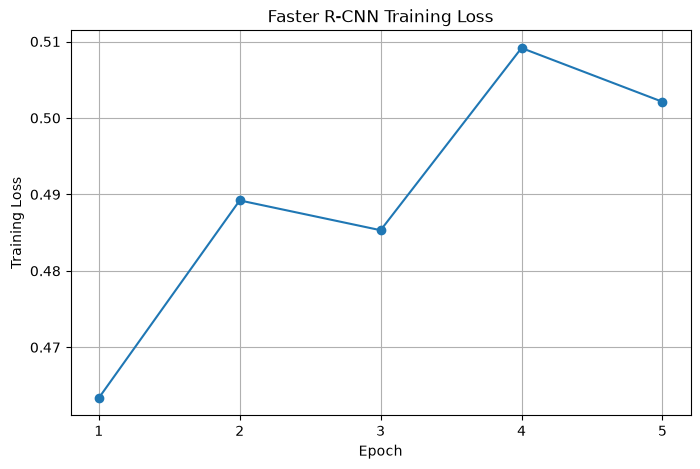

In [153]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, FASTER_RCNN_EPOCHS + 1),
    faster_train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Faster R-CNN Training Loss")

plt.xticks(
    range(1, FASTER_RCNN_EPOCHS + 1)
)

plt.grid(True)

plt.show()

In [154]:
torch.save(
    faster_rcnn_model.state_dict(),
    "faster_rcnn_pistol_detection.pth"
)

print(
    "Faster R-CNN model saved successfully."
)

Faster R-CNN model saved successfully.


In [155]:
print("Model:", "Faster R-CNN")
print(
    "Training samples:",
    len(faster_train_dataset)
)
print(
    "Validation samples:",
    len(faster_val_dataset)
)
print(
    "Test samples:",
    len(faster_test_dataset)
)
print(
    "Final training loss:",
    faster_train_losses[-1]
)

Model: Faster R-CNN
Training samples: 2592
Validation samples: 555
Test samples: 556
Final training loss: 0.5021165502430113


In [156]:
faster_rcnn_model.eval()

faster_all_labels = []
faster_all_predictions = []

faster_detection_ious = []
faster_detection_scores = []

if device.type == "cuda":
    torch.cuda.synchronize()

start_time = time.time()

with torch.no_grad():

    for images, targets in faster_val_loader:

        images = [
            image.to(device, non_blocking=True)
            for image in images
        ]

        outputs = faster_rcnn_model(images)

        for target, output in zip(targets, outputs):

            true_has_pistol = (
                target["labels"].numel() > 0
            )

            scores = output["scores"].cpu()
            boxes = output["boxes"].cpu()

            # Keep detections with confidence >= 0.5
            keep = scores >= 0.5

            scores = scores[keep]
            boxes = boxes[keep]

            predicted_has_pistol = (
                len(scores) > 0
            )

            faster_all_labels.append(
                int(true_has_pistol)
            )

            faster_all_predictions.append(
                int(predicted_has_pistol)
            )

            if (
                true_has_pistol
                and predicted_has_pistol
            ):

                # Highest-confidence detection
                best_idx = torch.argmax(scores)

                predicted_box = boxes[
                    best_idx
                ].numpy()

                true_box = target["boxes"][0].numpy()

                # Convert XYXY -> XCYCWH
                px1, py1, px2, py2 = predicted_box

                predicted_box_xywh = [
                    ((px1 + px2) / 2) / 416,
                    ((py1 + py2) / 2) / 416,
                    (px2 - px1) / 416,
                    (py2 - py1) / 416
                ]

                tx1, ty1, tx2, ty2 = true_box

                true_box_xywh = [
                    ((tx1 + tx2) / 2) / 416,
                    ((ty1 + ty2) / 2) / 416,
                    (tx2 - tx1) / 416,
                    (ty2 - ty1) / 416
                ]

                iou = proposal_iou(
                    predicted_box_xywh,
                    true_box_xywh
                )

                faster_detection_ious.append(iou)

                faster_detection_scores.append(
                    scores[best_idx].item()
                )

if device.type == "cuda":
    torch.cuda.synchronize()

end_time = time.time()

faster_inference_time = (
    end_time - start_time
)

print(
    "Validation images evaluated:",
    len(faster_all_labels)
)

print(
    "Images with predicted pistol:",
    sum(faster_all_predictions)
)

print(
    "True pistol images:",
    sum(faster_all_labels)
)

print(
    f"Inference time: "
    f"{faster_inference_time:.2f} seconds"
)

Validation images evaluated: 555
Images with predicted pistol: 248
True pistol images: 415
Inference time: 14.03 seconds


In [159]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Metrics imported successfully.")

Metrics imported successfully.


In [160]:
faster_accuracy = accuracy_score(
    faster_all_labels,
    faster_all_predictions
)

faster_precision = precision_score(
    faster_all_labels,
    faster_all_predictions,
    zero_division=0
)

faster_recall = recall_score(
    faster_all_labels,
    faster_all_predictions,
    zero_division=0
)

faster_f1 = f1_score(
    faster_all_labels,
    faster_all_predictions,
    zero_division=0
)

faster_cm = confusion_matrix(
    faster_all_labels,
    faster_all_predictions
)

print(
    f"Accuracy:  {faster_accuracy * 100:.2f}%"
)

print(
    f"Precision: {faster_precision:.4f}"
)

print(
    f"Recall:    {faster_recall:.4f}"
)

print(
    f"F1 Score:  {faster_f1:.4f}"
)

print("\nConfusion Matrix:")
print(faster_cm)

Accuracy:  65.23%
Precision: 0.9476
Recall:    0.5663
F1 Score:  0.7089

Confusion Matrix:
[[127  13]
 [180 235]]


In [161]:
if len(faster_detection_ious) > 0:

    faster_mean_iou = np.mean(
        faster_detection_ious
    )

    faster_iou_50 = np.mean(
        np.array(faster_detection_ious) >= 0.5
    )

    print(
        "Positive detections evaluated:",
        len(faster_detection_ious)
    )

    print(
        f"Mean IoU: "
        f"{faster_mean_iou:.4f}"
    )

    print(
        f"IoU >= 0.50 Detection Rate: "
        f"{faster_iou_50 * 100:.2f}%"
    )

else:

    faster_mean_iou = 0.0
    faster_iou_50 = 0.0

    print(
        "No true-positive detections found."
    )

Positive detections evaluated: 235
Mean IoU: 0.7272
IoU >= 0.50 Detection Rate: 85.96%


In [162]:
faster_image_fps = (
    len(faster_all_labels)
    / faster_inference_time
)

print(
    f"Images evaluated: "
    f"{len(faster_all_labels)}"
)

print(
    f"Inference time: "
    f"{faster_inference_time:.2f} seconds"
)

print(
    f"Image FPS: "
    f"{faster_image_fps:.2f}"
)

Images evaluated: 555
Inference time: 14.03 seconds
Image FPS: 39.56


In [163]:
faster_rcnn_results = {
    "model": "Faster R-CNN",
    "accuracy": faster_accuracy,
    "precision": faster_precision,
    "recall": faster_recall,
    "f1": faster_f1,
    "mean_iou": faster_mean_iou,
    "iou_50_rate": faster_iou_50,
    "inference_time": faster_inference_time,
    "fps": faster_image_fps
}

print("\nFaster R-CNN Results")
print("-" * 35)

for key, value in faster_rcnn_results.items():
    print(f"{key}: {value}")


Faster R-CNN Results
-----------------------------------
model: Faster R-CNN
accuracy: 0.6522522522522523
precision: 0.9475806451612904
recall: 0.5662650602409639
f1: 0.7088989441930619
mean_iou: 0.7272403836250305
iou_50_rate: 0.8595744680851064
inference_time: 14.029857397079468
fps: 39.5584918857074


In [164]:
all_results = [
    {
        "model": "Custom CNN",
        **custom_results
    },
    rcnn_results,
    fast_rcnn_results,
    faster_rcnn_results
]

comparison_df = pd.DataFrame(all_results)

comparison_df

NameError: name 'custom_results' is not defined

In [165]:
custom_results = {
    "model": "Custom CNN",
    "accuracy": 0.9640,
    "precision": None,
    "recall": None,
    "f1": None,
    "mean_iou": 0.4042,
    "iou_50_rate": 0.3409,
    "inference_time": None,
    "fps": None
}

print("Custom CNN results stored successfully.")

for key, value in custom_results.items():
    print(f"{key}: {value}")

Custom CNN results stored successfully.
model: Custom CNN
accuracy: 0.964
precision: None
recall: None
f1: None
mean_iou: 0.4042
iou_50_rate: 0.3409
inference_time: None
fps: None


In [166]:
all_results = [
    custom_results,
    rcnn_results,
    fast_rcnn_results,
    faster_rcnn_results
]

comparison_df = pd.DataFrame(all_results)

comparison_df

,model,accuracy,precision,recall,f1,mean_iou,iou_50_rate,inference_time,fps
0,Custom CNN,0.964000,NaN,NaN,NaN,0.404200,0.340900,NaN,NaN
1,R-CNN,0.763583,0.201717,0.928274,0.331416,0.667716,0.862262,28.813144,528.925272
2,Fast R-CNN,0.884908,0.336768,0.849272,0.482290,0.704599,0.869033,32.406440,470.276892
3,Faster R-CNN,0.652252,0.947581,0.566265,0.708899,0.727240,0.859574,14.029857,39.558492


In [167]:
display(
    comparison_df[
        [
            "model",
            "accuracy",
            "precision",
            "recall",
            "f1",
            "mean_iou",
            "iou_50_rate",
            "inference_time",
            "fps"
        ]
    ]
)

,model,accuracy,precision,recall,f1,mean_iou,iou_50_rate,inference_time,fps
0,Custom CNN,0.964000,NaN,NaN,NaN,0.404200,0.340900,NaN,NaN
1,R-CNN,0.763583,0.201717,0.928274,0.331416,0.667716,0.862262,28.813144,528.925272
2,Fast R-CNN,0.884908,0.336768,0.849272,0.482290,0.704599,0.869033,32.406440,470.276892
3,Faster R-CNN,0.652252,0.947581,0.566265,0.708899,0.727240,0.859574,14.029857,39.558492


In [168]:
comparison_clean = comparison_df[
    [
        "model",
        "accuracy",
        "precision",
        "recall",
        "f1",
        "mean_iou",
        "iou_50_rate",
        "inference_time",
        "fps"
    ]
].copy()

comparison_clean.columns = [
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Mean IoU",
    "IoU@0.50",
    "Inference Time (s)",
    "FPS"
]

comparison_clean

,Model,Accuracy,Precision,Recall,F1,Mean IoU,IoU@0.50,Inference Time (s),FPS
0,Custom CNN,0.964000,NaN,NaN,NaN,0.404200,0.340900,NaN,NaN
1,R-CNN,0.763583,0.201717,0.928274,0.331416,0.667716,0.862262,28.813144,528.925272
2,Fast R-CNN,0.884908,0.336768,0.849272,0.482290,0.704599,0.869033,32.406440,470.276892
3,Faster R-CNN,0.652252,0.947581,0.566265,0.708899,0.727240,0.859574,14.029857,39.558492


In [169]:
comparison_display = comparison_clean.copy()

for column in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Mean IoU",
    "IoU@0.50"
]:
    comparison_display[column] = (
        comparison_display[column] * 100
    ).round(2)

comparison_display[
    "Inference Time (s)"
] = comparison_display[
    "Inference Time (s)"
].round(2)

comparison_display[
    "FPS"
] = comparison_display[
    "FPS"
].round(2)

comparison_display

,Model,Accuracy,Precision,Recall,F1,Mean IoU,IoU@0.50,Inference Time (s),FPS
0,Custom CNN,96.40,NaN,NaN,NaN,40.42,34.09,NaN,NaN
1,R-CNN,76.36,20.17,92.83,33.14,66.77,86.23,28.81,528.93
2,Fast R-CNN,88.49,33.68,84.93,48.23,70.46,86.90,32.41,470.28
3,Faster R-CNN,65.23,94.76,56.63,70.89,72.72,85.96,14.03,39.56


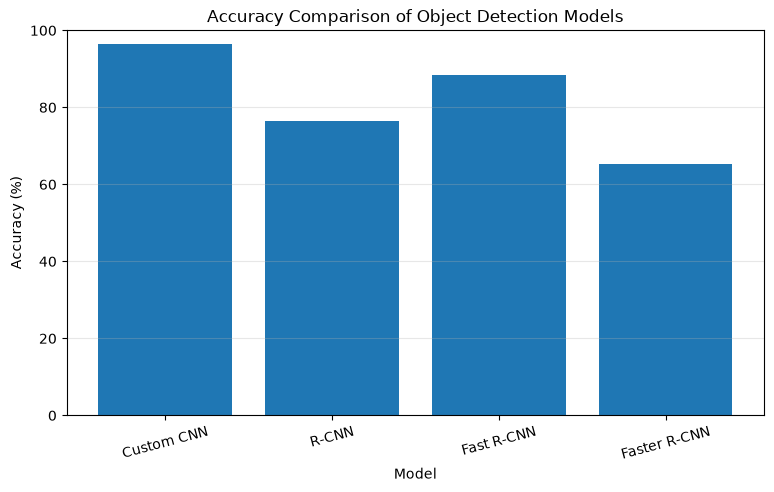

In [170]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_display["Model"],
    comparison_display["Accuracy"]
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Model")
plt.title("Accuracy Comparison of Object Detection Models")

plt.ylim(0, 100)
plt.xticks(rotation=15)

plt.grid(axis="y", alpha=0.3)

plt.show()

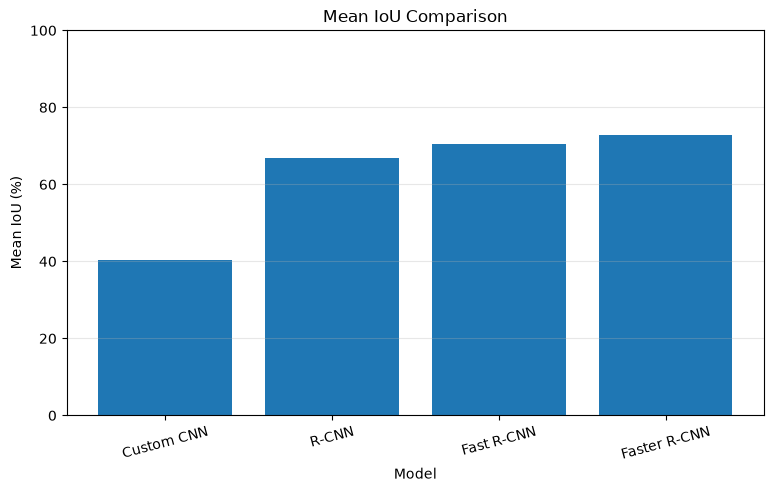

In [171]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison_display["Model"],
    comparison_display["Mean IoU"]
)

plt.ylabel("Mean IoU (%)")
plt.xlabel("Model")
plt.title("Mean IoU Comparison")

plt.ylim(0, 100)
plt.xticks(rotation=15)

plt.grid(axis="y", alpha=0.3)

plt.show()

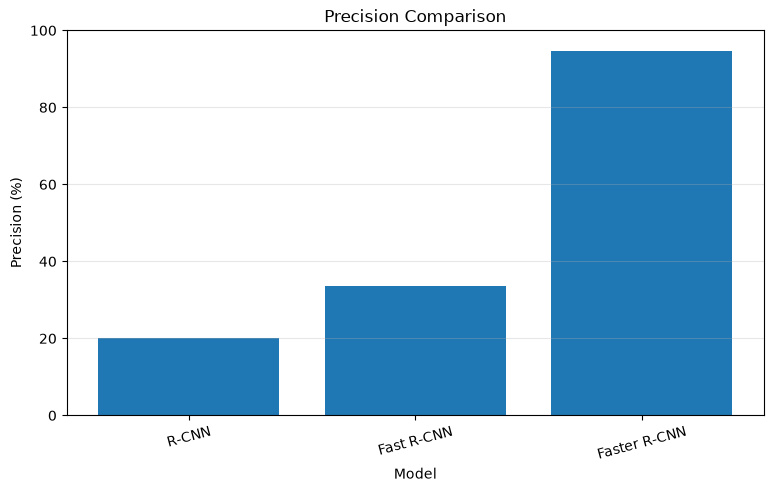

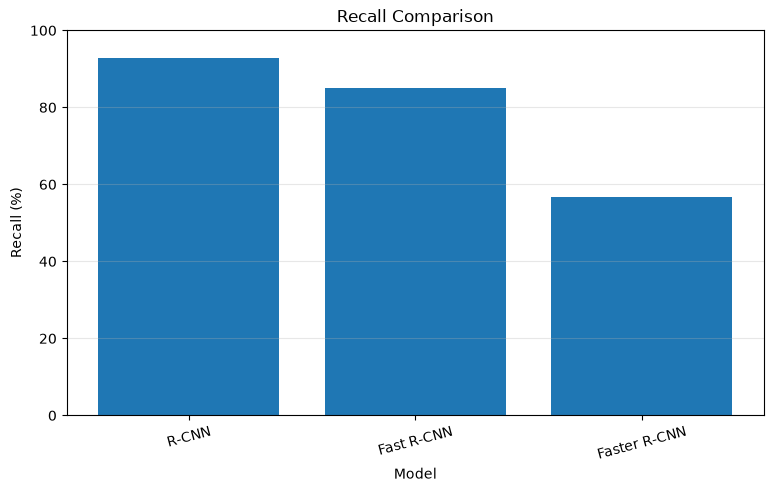

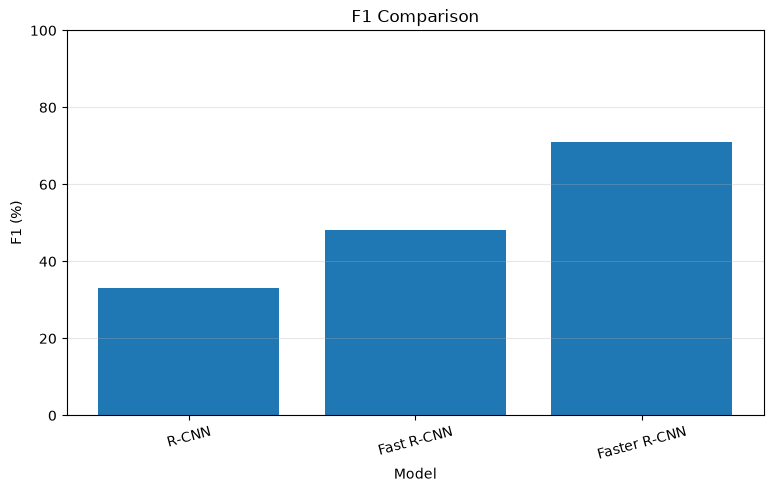

In [172]:
metrics = [
    "Precision",
    "Recall",
    "F1"
]

for metric in metrics:

    plt.figure(figsize=(9, 5))

    plt.bar(
        comparison_display["Model"],
        comparison_display[metric]
    )

    plt.ylabel(f"{metric} (%)")
    plt.xlabel("Model")
    plt.title(
        f"{metric} Comparison"
    )

    plt.ylim(0, 100)
    plt.xticks(rotation=15)

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()

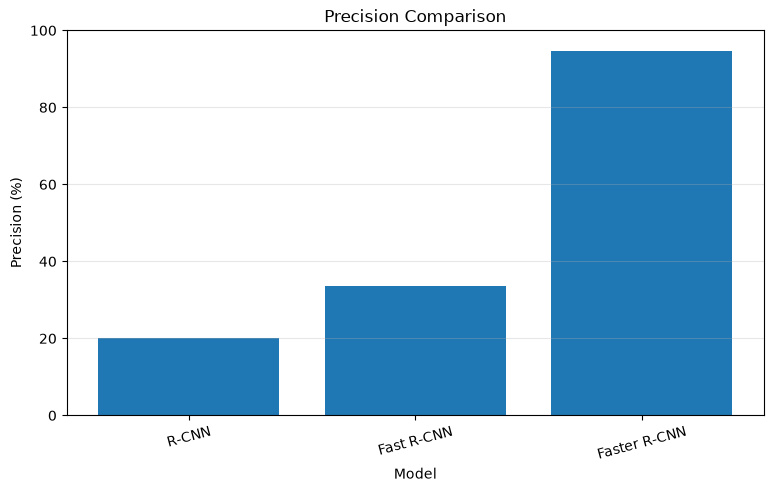

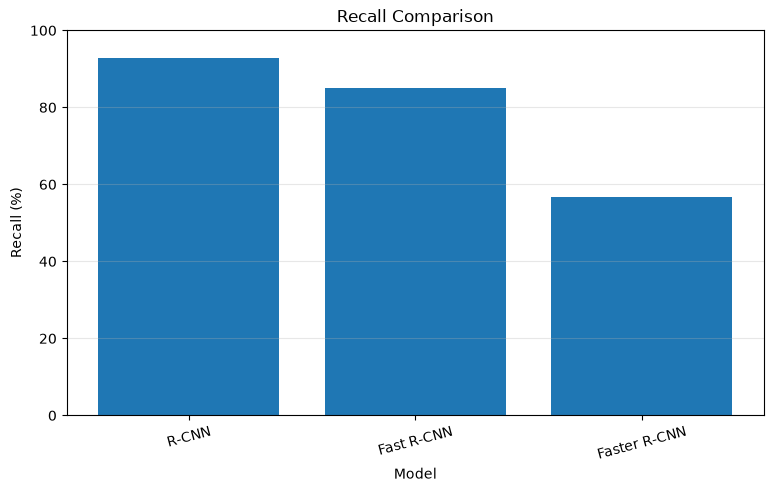

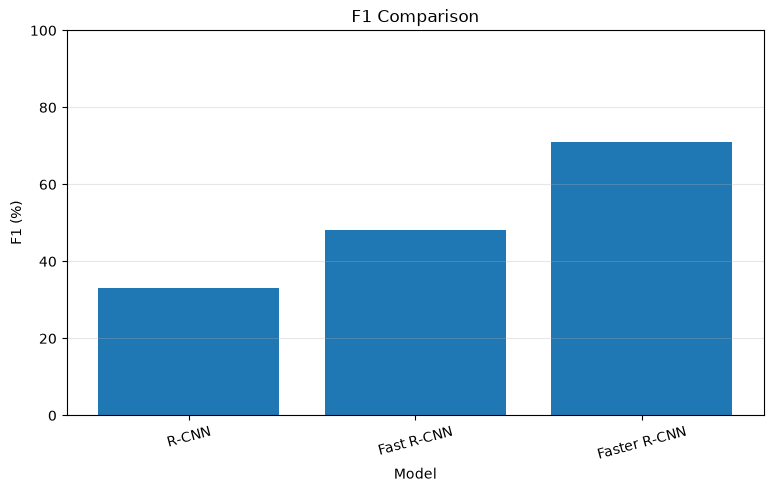

In [173]:
metrics = [
    "Precision",
    "Recall",
    "F1"
]

for metric in metrics:

    plt.figure(figsize=(9, 5))

    plt.bar(
        comparison_display["Model"],
        comparison_display[metric]
    )

    plt.ylabel(f"{metric} (%)")
    plt.xlabel("Model")
    plt.title(
        f"{metric} Comparison"
    )

    plt.ylim(0, 100)
    plt.xticks(rotation=15)

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()